In [1]:
import sys
import platform

print("Python version:", sys.version.split()[0])
print("Operating system:", platform.system())
print("Machine architecture:", platform.machine())

try:
    import torch
    import torchvision

    print("PyTorch version:", torch.__version__)
    print("Torchvision version:", torchvision.__version__)
    print("CUDA available:", torch.cuda.is_available())
    print("MPS available:", torch.backends.mps.is_available())

except ModuleNotFoundError as error:
    print("Missing package:", error.name)

Python version: 3.13.9
Operating system: Darwin
Machine architecture: arm64
PyTorch version: 2.14.0
Torchvision version: 0.29.0
CUDA available: False
MPS available: True


In [ ]:
import torch

x = torch.tensor([
    [1.0, 2.0, 3.0],
    [4.0, 5.0, 6.0]
], dtype=torch.float32)#把数字创建成Tensor（张量），2个样本

print("Tensor:")
print(x)
print("Shape:", x.shape)
print("Number of dimensions:", x.ndim)#几个轴
print("Data type:", x.dtype)
print("Device:", x.device)
print("First sample:", x[0])#取第一行
print("First feature:", x[:, 0])#取第一列

Tensor:
tensor([[1., 2., 3.],
        [4., 5., 6.]])
Shape: torch.Size([2, 3])
Number of dimensions: 2
Data type: torch.float32
Device: cpu
First sample: tensor([1., 2., 3.])
First feature: tensor([1., 4.])


创建一个二维张量，2 个样本，每个样本 3 个特征

In [ ]:
print("Original tensor:")
print(x)

print("Add 10:")
print(x + 10)

print("Multiply by 2:")
print(x * 2)

print("Overall mean:", x.mean())#全部元素求平均
print("Mean of each feature:", x.mean(dim=0))#每一列求平均
print("Mean of each sample:", x.mean(dim=1))#每一行求平均

Original tensor:
tensor([[1., 2., 3.],
        [4., 5., 6.]])
Add 10:
tensor([[11., 12., 13.],
        [14., 15., 16.]])
Multiply by 2:
tensor([[ 2.,  4.,  6.],
        [ 8., 10., 12.]])
Overall mean: tensor(3.5000)
Mean of each feature: tensor([2.5000, 3.5000, 4.5000])
Mean of each sample: tensor([2., 5.])


1.这里的 tensor(3.5000) 只有一个数值，是一个零维张量，也叫标量张量。

2.理解 dim 的关键是：指定哪个轴，就沿着哪个轴把数值汇总起来。


In [ ]:
values = torch.arange(12, dtype=torch.float32)
images = values.reshape(2, 1, 2, 3)#把数字组织成图像批次：两张图像，每张有一个通道，高度为 2，宽度为 3。

print("Original values:")
print(values)

print("Image batch shape:", images.shape)
print("First image:")
print(images[0, 0])#查看第一张图像的第一个通道

flattened = images.reshape(images.shape[0], -1)#把每张图像展开成一行

print("Flattened shape:", flattened.shape)
print("Flattened images:")
print(flattened)

Original values:
tensor([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11.])
Image batch shape: torch.Size([2, 1, 2, 3])
First image:
tensor([[0., 1., 2.],
        [3., 4., 5.]])
Flattened shape: torch.Size([2, 6])
Flattened images:
tensor([[ 0.,  1.,  2.,  3.,  4.,  5.],
        [ 6.,  7.,  8.,  9., 10., 11.]])


按照 PyTorch 图像处理中常见的顺序组织数据：
| 位置 | 含义 | 本例的大小 |
|---|---|---:|
| 第一个轴 | 图像数量 | 2 |
| 第二个轴 | 通道数量 | 1 |
| 第三个轴 | 图像高度，即行数 | 2 |
| 第四个轴 | 图像宽度，即列数 | 3 |

flatten（展平）：把每张图像的像素按顺序排成一个向量。

images.reshape(images.shape[0], -1)

images.shape[0]。它取出形状中的第一个数，这里是 2，也就是图像数量。

Training samples: 60000
Test samples: 10000
Image shape: torch.Size([1, 28, 28])
Image data type: torch.float32
Pixel range: 0.0 1.0
Label: 5


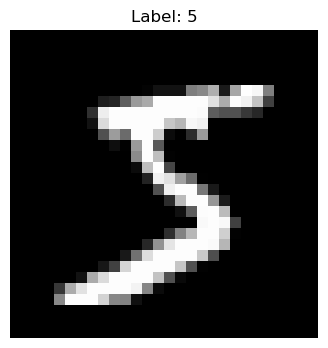

In [ ]:
#加载 MNIST，并查看一张手写数字图像。
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

transform = transforms.ToTensor()#把图像转换成 Tensor：1.把图像转换成 PyTorch 的浮点 Tensor，形状为 [通道数, 高度, 宽度]。2.把像素值除以 255，缩放到 0～1。

train_dataset = datasets.MNIST(
    root="data",#把数据保存在当前 Python 工作目录下的 data 文件夹中
    train=True,#读取 MNIST 官方训练集
    download=True,#	如果本地缺少数据，就下载
    transform=transform#取出图像时，使用刚才定义的转换操作
)#创建数据集对象

test_dataset = datasets.MNIST(
    root="data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))

image, label = train_dataset[0]#取出第一条样本

print("Image shape:", image.shape)
print("Image data type:", image.dtype)
print("Pixel range:", image.min().item(), image.max().item())
print("Label:", label)

plt.figure(figsize=(4, 4))
plt.imshow(image[0], cmap="gray", vmin=0, vmax=1)
plt.title(f"Label: {label}")
plt.axis("off")
plt.show()

① 我们导入了什么？
| 代码 | 用途 |
|---|---|
| `matplotlib.pyplot` | 显示图像、绘制图表 |
| `datasets` | 提供 MNIST 等现成的数据集 |
| `transforms` | 提供图像转换和预处理操作 |

这里的 torchvision 是与 PyTorch 配合使用的视觉工具包。

In [ ]:
from torch.utils.data import DataLoader

seed = 42
torch.manual_seed(seed)

batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,#打乱训练样本顺序
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

images, labels = next(iter(train_loader))

print("Training batches:", len(train_loader))
print("Test batches:", len(test_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10])

Training batches: 938
Test batches: 157
Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])
First 10 labels: tensor([1, 2, 8, 5, 2, 6, 9, 9, 9, 4])


① Dataset 和 DataLoader 有什么区别？
| 对象 | 在当前项目中的作用 |
|---|---|
| `train_dataset` | 提供训练样本；可以按编号取出图像及其标签 |
| `train_loader` | 按指定规则取出样本，并组合成批次 |

⑥ images, labels = next(iter(train_loader))：取出一个批次

这一行从内向外理解：
| 代码 | 含义 |
|---|---|
| `iter(train_loader)` | 创建一个可以逐批读取数据的迭代器 |
| `next(...)` | 从这个迭代器中取出下一批数据 |
| `images, labels = ...` | 分别保存这一批图像和对应标签 |

In [8]:
from torch import nn

class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(784, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.reshape(x.shape[0], -1)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

torch.manual_seed(seed)
model = NeuralNetwork()

outputs = model(images)

print(model)
print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

NeuralNetwork(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
  (relu): ReLU()
)
Input shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])


In [ ]:
#计算损失
loss_fn = nn.CrossEntropyLoss()

outputs = model(images)
loss = loss_fn(outputs, labels)

predictions = outputs.argmax(dim=1)
correct = predictions == labels
accuracy = correct.float().mean()

print(f"Batch loss: {loss.item():.4f}")
print(f"Batch accuracy: {accuracy.item():.2%}")
print("First 10 predictions:", predictions[:10])
print("First 10 labels:", labels[:10])

Batch loss: 2.3150
Batch accuracy: 6.25%
First 10 predictions: tensor([4, 9, 4, 4, 4, 4, 4, 4, 4, 4])
First 10 labels: tensor([1, 2, 8, 5, 2, 6, 9, 9, 9, 4])


In [ ]:
#计算梯度
model.zero_grad(set_to_none=True)

print("Gradient before backward:", model.fc1.weight.grad)

outputs = model(images)
loss = loss_fn(outputs, labels)

loss.backward()#执行反向传播

print("First layer weight shape:", model.fc1.weight.shape)
print("First layer gradient shape:", model.fc1.weight.grad.shape)
print("Mean absolute gradient:", model.fc1.weight.grad.abs().mean().item())
print("Output layer bias gradients:", model.fc3.bias.grad)

Gradient before backward: None
First layer weight shape: torch.Size([128, 784])
First layer gradient shape: torch.Size([128, 784])
Mean absolute gradient: 0.0004698082630056888
Output layer bias gradients: tensor([-0.0328,  0.0636, -0.0359, -0.0067,  0.0360,  0.0460, -0.0532,  0.0002,
         0.0135, -0.0309])


In [11]:
#使用SGD调整参数
learning_rate = 0.01
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

optimizer.zero_grad(set_to_none=True)

outputs = model(images)
loss = loss_fn(outputs, labels)
loss_before = loss.item()

loss.backward()
optimizer.step()

with torch.no_grad():
    outputs_after = model(images)
    loss_after = loss_fn(outputs_after, labels).item()

print(f"Loss before update: {loss_before:.6f}")
print(f"Loss after update: {loss_after:.6f}")
print(f"Loss decrease: {loss_before - loss_after:.6f}")

Loss before update: 2.314953
Loss after update: 2.313600
Loss decrease: 0.001353


In [ ]:
#训练一个epoch（先准备 初始化模型）
if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

torch.manual_seed(seed)

model = NeuralNetwork().to(device)

learning_rate = 0.01
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

print("Training device:", device)

Training device: mps


In [13]:
#完整训练
model.train()

total_loss = 0.0
total_correct = 0
total_samples = 0

for batch_index, (batch_images, batch_labels) in enumerate(train_loader, start=1):
    batch_images = batch_images.to(device)
    batch_labels = batch_labels.to(device)

    optimizer.zero_grad(set_to_none=True)

    batch_outputs = model(batch_images)
    batch_loss = loss_fn(batch_outputs, batch_labels)

    batch_loss.backward()
    optimizer.step()

    current_batch_size = batch_labels.shape[0]
    total_loss += batch_loss.item() * current_batch_size
    total_correct += (batch_outputs.argmax(dim=1) == batch_labels).sum().item()
    total_samples += current_batch_size

    if batch_index % 200 == 0 or batch_index == len(train_loader):
        print(f"Batch {batch_index}/{len(train_loader)} | Loss: {batch_loss.item():.4f}")

epoch_train_loss = total_loss / total_samples
epoch_train_accuracy = total_correct / total_samples

print(f"Epoch training loss: {epoch_train_loss:.4f}")
print(f"Epoch training accuracy: {epoch_train_accuracy:.2%}")

Batch 200/938 | Loss: 2.2130
Batch 400/938 | Loss: 1.8399
Batch 600/938 | Loss: 1.4104
Batch 800/938 | Loss: 1.0427
Batch 938/938 | Loss: 0.6190
Epoch training loss: 1.6658
Epoch training accuracy: 55.24%


| 变量 | 记录的内容 |
|---|---|
| `total_loss` | 已处理样本的损失总和 |
| `total_correct` | 已处理样本中预测正确的数量 |
| `total_samples` | 已经处理的样本数量 |

In [ ]:
#创建评估函数
def evaluate(model, data_loader, loss_fn, device):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for batch_images, batch_labels in data_loader:
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)

            batch_outputs = model(batch_images)
            batch_loss = loss_fn(batch_outputs, batch_labels)

            current_batch_size = batch_labels.shape[0]
            total_loss += batch_loss.item() * current_batch_size
            total_correct += (batch_outputs.argmax(dim=1) == batch_labels).sum().item()
            total_samples += current_batch_size

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return average_loss, accuracy

test_loss, test_accuracy = evaluate(model, test_loader, loss_fn, device)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

Test loss: 0.7603
Test accuracy: 82.01%


评估函数评估什么？


| 参数 | 当前传入的对象 | 用途 |
|---|---|---|
| `model` | 已训练一轮的模型 | 计算预测 |
| `data_loader` | `test_loader` | 提供要评估的数据 |
| `loss_fn` | 交叉熵损失函数 | 计算损失 |
| `device` | 当前使用的 MPS 或 CPU | 指定数据计算设备 |

In [ ]:
#训练第二个epoch
def train_one_epoch(model, data_loader, loss_fn, optimizer, device):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for batch_images, batch_labels in data_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        batch_outputs = model(batch_images)
        batch_loss = loss_fn(batch_outputs, batch_labels)

        batch_loss.backward()
        optimizer.step()

        current_batch_size = batch_labels.shape[0]
        total_loss += batch_loss.item() * current_batch_size
        total_correct += (batch_outputs.argmax(dim=1) == batch_labels).sum().item()
        total_samples += current_batch_size

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return average_loss, accuracy

函数的输入

| 参数 | 用途 |
|---|---|
| `model` | 要训练的模型 |
| `data_loader` | 提供训练批次 |
| `loss_fn` | 计算预测损失 |
| `optimizer`（新增） | 根据梯度更新模型参数 |
| `device` | 指定计算设备 |

In [16]:
train_loss_2, train_accuracy_2 = train_one_epoch(
    model, train_loader, loss_fn, optimizer, device
)

test_loss_2, test_accuracy_2 = evaluate(
    model, test_loader, loss_fn, device
)

print(f"Epoch 2 training loss: {train_loss_2:.4f}")
print(f"Epoch 2 training accuracy: {train_accuracy_2:.2%}")
print(f"Epoch 2 test loss: {test_loss_2:.4f}")
print(f"Epoch 2 test accuracy: {test_accuracy_2:.2%}")

Epoch 2 training loss: 0.5494
Epoch 2 training accuracy: 85.59%
Epoch 2 test loss: 0.4141
Epoch 2 test accuracy: 88.77%


In [17]:
#记录前两轮结果
history = [
    {
        "epoch": 1,
        "train_loss": epoch_train_loss,
        "train_accuracy": epoch_train_accuracy,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy
    },
    {
        "epoch": 2,
        "train_loss": train_loss_2,
        "train_accuracy": train_accuracy_2,
        "test_loss": test_loss_2,
        "test_accuracy": test_accuracy_2
    }
]

print("Recorded epochs:", len(history))

Recorded epochs: 2


In [18]:
#完成剩下三轮
total_epochs = 5
start_epoch = history[-1]["epoch"] + 1

for epoch in range(start_epoch, total_epochs + 1):
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, loss_fn, optimizer, device
    )

    current_test_loss, current_test_accuracy = evaluate(
        model, test_loader, loss_fn, device
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "test_loss": current_test_loss,
        "test_accuracy": current_test_accuracy
    })

    print(
        f"Epoch {epoch}/{total_epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train accuracy: {train_accuracy:.2%} | "
        f"Test loss: {current_test_loss:.4f} | "
        f"Test accuracy: {current_test_accuracy:.2%}"
    )

Epoch 3/5 | Train loss: 0.3933 | Train accuracy: 89.03% | Test loss: 0.3478 | Test accuracy: 90.21%
Epoch 4/5 | Train loss: 0.3448 | Train accuracy: 90.25% | Test loss: 0.3174 | Test accuracy: 91.02%
Epoch 5/5 | Train loss: 0.3157 | Train accuracy: 91.06% | Test loss: 0.2941 | Test accuracy: 91.90%


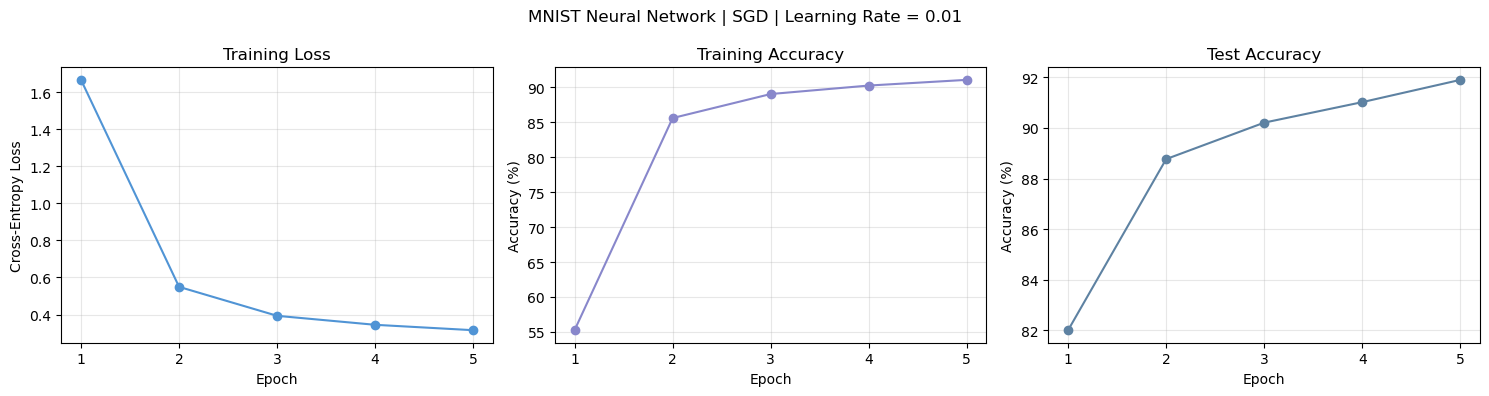

In [19]:
#画图
import matplotlib.pyplot as plt
import pandas as pd

history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(
    history_df["epoch"], history_df["train_loss"],
    marker="o", color="#5094D5"
)
axes[0].set_title("Training Loss")
axes[0].set_ylabel("Cross-Entropy Loss")

axes[1].plot(
    history_df["epoch"], history_df["train_accuracy"] * 100,
    marker="o", color="#8887CB"
)
axes[1].set_title("Training Accuracy")
axes[1].set_ylabel("Accuracy (%)")

axes[2].plot(
    history_df["epoch"], history_df["test_accuracy"] * 100,
    marker="o", color="#5E82A2"
)
axes[2].set_title("Test Accuracy")
axes[2].set_ylabel("Accuracy (%)")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_xticks(history_df["epoch"])
    ax.grid(True, alpha=0.3)

fig.suptitle("MNIST Neural Network | SGD | Learning Rate = 0.01")
plt.tight_layout()
plt.show()

In [20]:
#准备学习率对比实验
def run_experiment(learning_rate, epochs=5, seed=42):
    torch.manual_seed(seed)
    generator = torch.Generator().manual_seed(seed)

    experiment_loader = DataLoader(
        train_dataset,
        batch_size=64,
        shuffle=True,
        num_workers=0,
        generator=generator
    )

    experiment_model = NeuralNetwork().to(device)
    experiment_optimizer = torch.optim.SGD(
        experiment_model.parameters(),
        lr=learning_rate
    )

    records = []

    for epoch in range(1, epochs + 1):
        train_loss, train_accuracy = train_one_epoch(
            experiment_model, experiment_loader,
            loss_fn, experiment_optimizer, device
        )

        test_loss, test_accuracy = evaluate(
            experiment_model, test_loader, loss_fn, device
        )

        records.append({
            "learning_rate": learning_rate,
            "seed": seed,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "test_loss": test_loss,
            "test_accuracy": test_accuracy
        })

        print(
            f"LR {learning_rate} | Epoch {epoch}/{epochs} | "
            f"Train loss: {train_loss:.4f} | "
            f"Train accuracy: {train_accuracy:.2%} | "
            f"Test loss: {test_loss:.4f} | "
            f"Test accuracy: {test_accuracy:.2%}"
        )

    return experiment_model, pd.DataFrame(records)

In [21]:
model_lr_0_1, history_lr_0_1 = run_experiment(
    learning_rate=0.1
)

history_lr_0_1

LR 0.1 | Epoch 1/5 | Train loss: 0.4939 | Train accuracy: 85.59% | Test loss: 0.2256 | Test accuracy: 93.42%
LR 0.1 | Epoch 2/5 | Train loss: 0.1919 | Train accuracy: 94.42% | Test loss: 0.1621 | Test accuracy: 95.33%
LR 0.1 | Epoch 3/5 | Train loss: 0.1317 | Train accuracy: 96.14% | Test loss: 0.1264 | Test accuracy: 96.21%
LR 0.1 | Epoch 4/5 | Train loss: 0.0978 | Train accuracy: 97.14% | Test loss: 0.0944 | Test accuracy: 97.19%
LR 0.1 | Epoch 5/5 | Train loss: 0.0783 | Train accuracy: 97.67% | Test loss: 0.0920 | Test accuracy: 97.11%


,learning_rate,seed,epoch,train_loss,train_accuracy,test_loss,test_accuracy
0,0.1,42,1,0.493862,0.855867,0.225635,0.9342
1,0.1,42,2,0.191856,0.944233,0.162144,0.9533
2,0.1,42,3,0.131697,0.961417,0.126391,0.9621
3,0.1,42,4,0.097817,0.971417,0.094373,0.9719
4,0.1,42,5,0.078321,0.976750,0.092049,0.9711


In [22]:
model_lr_0_01, history_lr_0_01 = run_experiment(
    learning_rate=0.01
)

history_lr_0_01

LR 0.01 | Epoch 1/5 | Train loss: 1.6662 | Train accuracy: 55.75% | Test loss: 0.7597 | Test accuracy: 81.98%
LR 0.01 | Epoch 2/5 | Train loss: 0.5509 | Train accuracy: 85.60% | Test loss: 0.4150 | Test accuracy: 88.62%
LR 0.01 | Epoch 3/5 | Train loss: 0.3938 | Train accuracy: 88.97% | Test loss: 0.3529 | Test accuracy: 89.91%
LR 0.01 | Epoch 4/5 | Train loss: 0.3458 | Train accuracy: 90.26% | Test loss: 0.3157 | Test accuracy: 91.09%
LR 0.01 | Epoch 5/5 | Train loss: 0.3161 | Train accuracy: 91.09% | Test loss: 0.3020 | Test accuracy: 91.38%


,learning_rate,seed,epoch,train_loss,train_accuracy,test_loss,test_accuracy
0,0.01,42,1,1.666241,0.557517,0.759730,0.8198
1,0.01,42,2,0.550854,0.855967,0.414955,0.8862
2,0.01,42,3,0.393835,0.889733,0.352932,0.8991
3,0.01,42,4,0.345818,0.902583,0.315663,0.9109
4,0.01,42,5,0.316096,0.910867,0.302023,0.9138


In [23]:
model_lr_0_001, history_lr_0_001 = run_experiment(
    learning_rate=0.001
)

history_lr_0_001

LR 0.001 | Epoch 1/5 | Train loss: 2.2941 | Train accuracy: 10.08% | Test loss: 2.2730 | Test accuracy: 13.68%
LR 0.001 | Epoch 2/5 | Train loss: 2.2479 | Train accuracy: 28.40% | Test loss: 2.2163 | Test accuracy: 44.63%
LR 0.001 | Epoch 3/5 | Train loss: 2.1780 | Train accuracy: 49.70% | Test loss: 2.1255 | Test accuracy: 51.75%
LR 0.001 | Epoch 4/5 | Train loss: 2.0630 | Train accuracy: 50.70% | Test loss: 1.9778 | Test accuracy: 50.89%
LR 0.001 | Epoch 5/5 | Train loss: 1.8863 | Train accuracy: 52.49% | Test loss: 1.7645 | Test accuracy: 55.73%


,learning_rate,seed,epoch,train_loss,train_accuracy,test_loss,test_accuracy
0,0.001,42,1,2.294062,0.100750,2.272999,0.1368
1,0.001,42,2,2.247861,0.284033,2.216318,0.4463
2,0.001,42,3,2.178049,0.496950,2.125489,0.5175
3,0.001,42,4,2.062962,0.507017,1.977821,0.5089
4,0.001,42,5,1.886280,0.524933,1.764543,0.5573


In [24]:
#合并实验结果
all_results = pd.concat(
    [history_lr_0_1, history_lr_0_01, history_lr_0_001],
    ignore_index=True
)

summary_df = all_results[all_results["epoch"] == 5].copy()

summary_df = summary_df[
    ["learning_rate", "train_loss", "train_accuracy", "test_loss", "test_accuracy"]
]

summary_df["train_accuracy"] = summary_df["train_accuracy"] * 100
summary_df["test_accuracy"] = summary_df["test_accuracy"] * 100

summary_df.round(4)

,learning_rate,train_loss,train_accuracy,test_loss,test_accuracy
4,0.100,0.0783,97.6750,0.0920,97.11
9,0.010,0.3161,91.0867,0.3020,91.38
14,0.001,1.8863,52.4933,1.7645,55.73


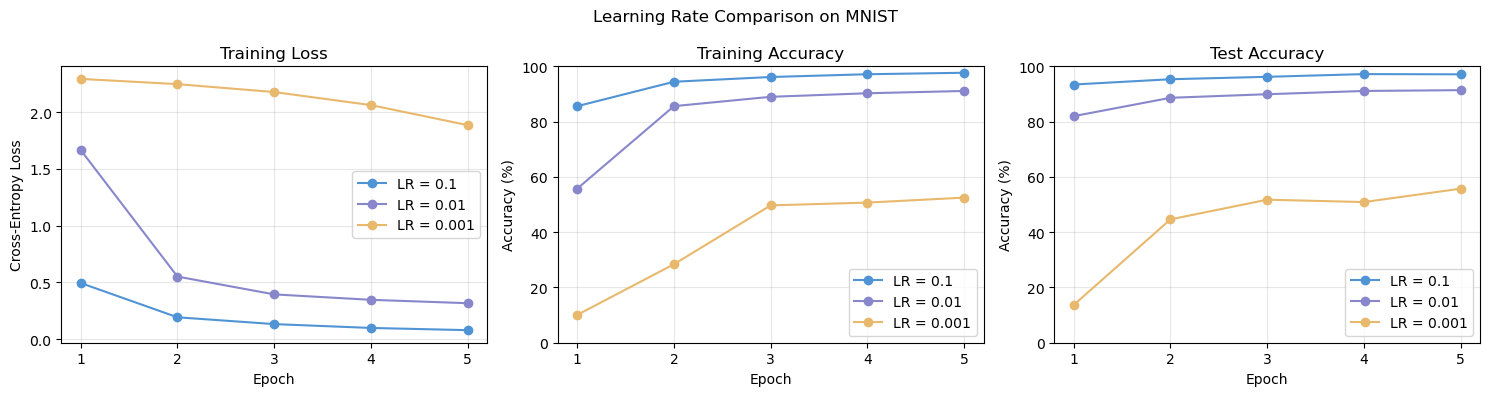

In [25]:
#绘制学习率对比图
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

settings = [
    (0.1, "#5094D5"),
    (0.01, "#8887CB"),
    (0.001, "#E8B86C")
]

for learning_rate, color in settings:
    results = all_results[all_results["learning_rate"] == learning_rate]
    label = f"LR = {learning_rate}"

    axes[0].plot(
        results["epoch"], results["train_loss"],
        marker="o", color=color, label=label
    )
    axes[1].plot(
        results["epoch"], results["train_accuracy"] * 100,
        marker="o", color=color, label=label
    )
    axes[2].plot(
        results["epoch"], results["test_accuracy"] * 100,
        marker="o", color=color, label=label
    )

axes[0].set_title("Training Loss")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[1].set_title("Training Accuracy")
axes[1].set_ylabel("Accuracy (%)")
axes[2].set_title("Test Accuracy")
axes[2].set_ylabel("Accuracy (%)")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_xticks(range(1, 6))
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[1].set_ylim(0, 100)
axes[2].set_ylim(0, 100)

fig.suptitle("Learning Rate Comparison on MNIST")
plt.tight_layout()
plt.show()

In [ ]:
#保存与重新加载模型
from pathlib import Path

output_dir = Path("week3_results")
output_dir.mkdir(parents=True, exist_ok=True)#`parents=True` 允许创建缺少的上级目录，`exist_ok=True` 允许文件夹已经存在

all_results.to_csv(output_dir / "learning_rate_history.csv", index=False)

summary_to_save = summary_df.rename(columns={
    "train_accuracy": "train_accuracy_percent",
    "test_accuracy": "test_accuracy_percent"
})
summary_to_save.to_csv(output_dir / "learning_rate_summary.csv", index=False)

fig.savefig(
    output_dir / "learning_rate_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

print("Results saved to:", output_dir.resolve())

Results saved to: /Users/cheeseowl/Desktop/科研/week3_results


In [ ]:
#保存参数
models_to_save = [
    (0.1, model_lr_0_1),
    (0.01, model_lr_0_01),
    (0.001, model_lr_0_001)
]

for learning_rate, trained_model in models_to_save:
    model_path = output_dir / f"mnist_mlp_lr_{learning_rate}.pth"
    torch.save(trained_model.state_dict(), model_path)
    print("Model saved:", model_path.name)

Model saved: mnist_mlp_lr_0.1.pth
Model saved: mnist_mlp_lr_0.01.pth
Model saved: mnist_mlp_lr_0.001.pth


In [28]:
#用刚保存的文件，恢复0.1学习率模型
loaded_model = NeuralNetwork()

saved_weights = torch.load(
    output_dir / "mnist_mlp_lr_0.1.pth",
    map_location="cpu",
    weights_only=True
)

loaded_model.load_state_dict(saved_weights)
loaded_model = loaded_model.to(device)

loaded_test_loss, loaded_test_accuracy = evaluate(
    loaded_model, test_loader, loss_fn, device
)

print(f"Loaded model test loss: {loaded_test_loss:.4f}")
print(f"Loaded model test accuracy: {loaded_test_accuracy:.2%}")

Loaded model test loss: 0.0920
Loaded model test accuracy: 97.11%


## 实验总结：MNIST 神经网络学习率对比

### 一、实验目的

使用 PyTorch 搭建一个全连接神经网络，对 MNIST 手写数字进行分类，并比较不同学习率对训练过程和分类表现的影响。

重点观察训练损失、训练准确率和测试准确率随训练轮次的变化。

### 二、实验设置

| 项目 | 设置 |
|---|---|
| 实验名称 | MNIST_MLP_SGD_lr0.1、MNIST_MLP_SGD_lr0.01、MNIST_MLP_SGD_lr0.001 |
| 数据集 | MNIST |
| 训练集大小 | 60,000 张图像 |
| 测试集大小 | 10,000 张图像 |
| 输入表示 | 将每张 28 × 28 的灰度图像展平为 784 个像素特征 |
| 像素预处理 | 使用 ToTensor，将像素值从 0～255 缩放到 0～1 |
| 网络结构 | 784 → 128 → 64 → 10 |
| 激活函数 | 前两个 Linear 层后使用 ReLU |
| 输出 | 对应数字 0～9 的 10 个原始类别分数（logits） |
| 损失函数 | 交叉熵损失（CrossEntropyLoss） |
| 优化器 | SGD，不使用动量和权重衰减 |
| 学习率 | 0.1、0.01、0.001 |
| 批次大小（Batch size） | 64 |
| 训练轮数（Epochs） | 每组 5 轮 |
| 随机种子 | 42 |

每组实验都重新创建模型和优化器，从头开始训练。

每组开始前，重新设置模型初始化的随机种子，并为训练 DataLoader 创建使用相同种子的独立随机数生成器，以控制初始参数和样本打乱顺序。

三组实验使用相同的数据、网络结构、批次大小和训练轮数，改变的因素为学习率。

### 三、训练与评估方法

每个训练批次依次完成以下操作：

1. 清除上一次保存的梯度。
2. 前向传播，计算类别分数。
3. 根据正确标签计算交叉熵损失。
4. 调用 loss.backward() 进行反向传播，计算参数梯度。
5. 调用 optimizer.step() 更新模型参数。

每轮训练结束后，使用当前模型评估整个测试集。

评估时使用 model.eval() 和 torch.no_grad()，不进行反向传播或参数更新。

训练损失按样本数量加权汇总，训练准确率通过累计预测正确的样本数计算。最后不足 64 个样本的批次也参与统计。

### 四、第五轮实验结果

| 学习率 | 训练损失 | 训练过程准确率（%） | 测试损失 | 测试准确率（%） |
|---|---:|---:|---:|---:|
| 0.1 | 0.0783 | 97.67 | 0.0920 | 97.11 |
| 0.01 | 0.3161 | 91.09 | 0.3020 | 91.38 |
| 0.001 | 1.8863 | 52.49 | 1.7645 | 55.73 |

训练指标是在每轮训练过程中累计的，此时模型参数不断变化；测试指标使用该轮结束后的固定模型计算。

因此，表中的训练准确率与测试准确率不能直接用于计算同一个固定模型的泛化差距。若要进一步分析过拟合，应使用同一个训练结束后的模型，分别重新评估训练集和测试集。

### 五、实验观察与分析

#### 1. 学习率明显影响了五轮内的学习速度

学习率为 0.1 时，第一轮结束后的测试准确率已经达到 93.42%。

相比之下，学习率为 0.01 和 0.001 时，第一轮测试准确率分别为 81.98% 和 13.68%。

这说明，在本次实验设置下，0.1 能够使模型更快达到较高的分类准确率。

#### 2. 学习率 0.1 的第五轮测试表现最好

在统一训练五轮后，学习率为 0.1 的模型获得了最高的测试准确率 97.11%，以及最低的测试损失 0.0920。

因此，在本次测试的三个学习率中，0.1 在当前网络和训练预算下表现最好。

#### 3. 学习率 0.01 能够有效学习，但五轮内进展较慢

学习率为 0.01 时，训练损失从第一轮的 1.6662 降到第五轮的 0.3161，测试准确率从 81.98% 提高到 91.38%。

这表明模型能够学习有效的分类规律，但在相同轮数内，表现低于学习率为 0.1 的模型。

#### 4. 学习率 0.001 的模型仍在学习

学习率为 0.001 时，训练损失从 2.2941 降到 1.8863，测试损失从 2.2730 降到 1.7645。

损失持续下降，说明模型仍在学习。第五轮测试准确率只有 55.73%，主要反映了它在当前五轮训练预算下进展较慢。

是否能通过增加训练轮数达到更高准确率，需要进一步实验验证。

#### 5. 测试损失与测试准确率不一定同步变化

学习率为 0.1 时，第四轮到第五轮的测试准确率从 97.19% 略降至 97.11%，但测试损失从 0.0944 继续降到 0.0920。

准确率只检查分数最高的类别是否正确；交叉熵损失还考虑模型给正确类别分配的概率。

因此，两项指标可能出现不同方向的小幅变化，不能仅凭这一次准确率下降就判定过拟合。

#### 6. 实验结论具有适用范围

本实验只比较了一个网络结构、一个随机种子和五轮训练下的三个学习率。

结果支持“0.1 在本次设置下表现最好”，但不能推广为“学习率越大越好”。

后续可以通过增加随机种子、延长训练轮数或测试其他学习率，检查结果是否稳定。

### 六、结果保存与模型加载验证

已保存以下内容：

- 三组实验的全部训练记录：learning_rate_history.csv。
- 三组第五轮结果：learning_rate_summary.csv。
- 学习率对比曲线：learning_rate_comparison.png。
- 三组模型在第五轮结束后的参数文件。

History 表中的准确率以 0～1 的比例保存；Summary 表中的准确率以百分数保存，并在列名中标记为 accuracy_percent。

模型使用 state_dict 保存参数。加载时，先创建相同结构的 NeuralNetwork，再使用 load_state_dict 恢复参数。

重新加载学习率为 0.1 的模型后，测试结果为：

- 测试损失：0.0920。
- 测试准确率：97.11%。

加载后的指标与保存前一致，说明模型参数保存与加载流程能够正常工作。